In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

df = pd.read_csv('../data/AmesHousing.csv')

df = df.drop(columns=['Order', 'PID'])

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.20, random_state=42)

print(f"Initial Train Shape: {X_train.shape}")
print(f"Initial Test Shape:  {X_test.shape}")

Initial Train Shape: (2344, 79)
Initial Test Shape:  (586, 79)


In [2]:
train_outlier_indices = X_train[(X_train['Gr Liv Area'] > 4000) & (y_train < 300000)].index
print(f"Removing {len(train_outlier_indices)} documented severe outliers from training data...")
X_train = X_train.drop(index=train_outlier_indices)
y_train = y_train.drop(index=train_outlier_indices)
print(f"Cleaned Train Shape: {X_train.shape}")
print(f"Test Shape (Untouched): {X_test.shape}")

Removing 2 documented severe outliers from training data...
Cleaned Train Shape: (2342, 79)
Test Shape (Untouched): (586, 79)


In [ ]:
def clean_missing_values(df_to_clean, train_ref_df=None):
    """
    Imputes missing values based on Ames domain rules:
    - Structural categorical NAs -> 'None'
    - Structural numeric NAs -> 0
    - MAR Lot Frontage -> Median of neighborhood 
    """
    df_clean = df_to_clean.copy()
    
    
    if train_ref_df is None:
        train_ref_df = df_clean

    
    none_cols = [
        'Pool QC', 'Misc Feature', 'Alley', 'Fence', 'Fireplace Qu',
        'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
        'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2',
        'Mas Vnr Type'
    ]
    for col in none_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].fillna('None')

    
    zero_cols = [
        'Garage Yr Blt', 'Garage Area', 'Garage Cars',
        'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
        'Bsmt Full Bath', 'Bsmt Half Bath', 'Mas Vnr Area'
    ]
    for col in zero_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].fillna(0)

    
    neighborhood_frontage_medians = train_ref_df.groupby('Neighborhood')['Lot Frontage'].median()
    global_frontage_median = train_ref_df['Lot Frontage'].median()
    
      
    df_clean['Lot Frontage'] = df_clean['Lot Frontage'].fillna(df_clean['Neighborhood'].map(neighborhood_frontage_medians))
    df_clean['Lot Frontage'] = df_clean['Lot Frontage'].fillna(global_frontage_median)

    
    
    cat_remaining = df_clean.select_dtypes(include=['object']).columns[df_clean.select_dtypes(include=['object']).isnull().any()]
    for col in cat_remaining:
        mode_val = train_ref_df[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mode_val)

    return df_clean


X_train_imputed = clean_missing_values(X_train)

X_test_imputed = clean_missing_values(X_test, train_ref_df=X_train)

print(f"Remaining Missing Values in X_train: {X_train_imputed.isnull().sum().sum()}")
print(f"Remaining Missing Values in X_test:  {X_test_imputed.isnull().sum().sum()}")


Remaining Missing Values in X_train: 0
Remaining Missing Values in X_test:  0


C:\Users\mindfire\AppData\Local\Temp\ipykernel_17376\3756689163.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_remaining = df_clean.select_dtypes(include=['object']).columns[df_clean.select_dtypes(include=['object']).isnull().any()]
C:\Users\mindfire\AppData\Local\Temp\ipykernel_17376\3756689163.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remov

In [5]:

quality_map = {
    'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5
}


exposure_map = {
    'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4
}


bsmt_fin_map = {
    'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6
}


ordinal_cols_standard = [
    'Exter Qual', 'Exter Cond', 'Bsmt Qual', 'Bsmt Cond', 
    'Heating QC', 'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 
    'Garage Cond', 'Pool QC'
]

def apply_ordinal_encoding(df_in):
    """Encodes ordinal features into meaningful integer ranks."""
    df_out = df_in.copy()
    
    
    for col in ordinal_cols_standard:
        if col in df_out.columns:
            df_out[col] = df_out[col].map(quality_map).fillna(0).astype(int)
            
   
    if 'Bsmt Exposure' in df_out.columns:
        df_out['Bsmt Exposure'] = df_out['Bsmt Exposure'].map(exposure_map).fillna(0).astype(int)
        
    for col in ['BsmtFin Type 1', 'BsmtFin Type 2']:
        if col in df_out.columns:
            df_out[col] = df_out[col].map(bsmt_fin_map).fillna(0).astype(int)
            
    
    if 'Central Air' in df_out.columns:
        df_out['Central Air'] = (df_out['Central Air'] == 'Y').astype(int)
        
    return df_out


X_train_encoded = apply_ordinal_encoding(X_train_imputed)
X_test_encoded = apply_ordinal_encoding(X_test_imputed)

print("Ordinal encoding complete!")
print("Sample of encoded Kitchen Qual & Overall Qual:")
X_train_encoded[['Overall Qual', 'Kitchen Qual', 'Exter Qual', 'Central Air']].head()


Ordinal encoding complete!
Sample of encoded Kitchen Qual & Overall Qual:


,Overall Qual,Kitchen Qual,Exter Qual,Central Air
381,7,3,3,1
834,5,3,3,1
1898,4,3,3,1
678,4,3,3,0
700,4,2,2,0


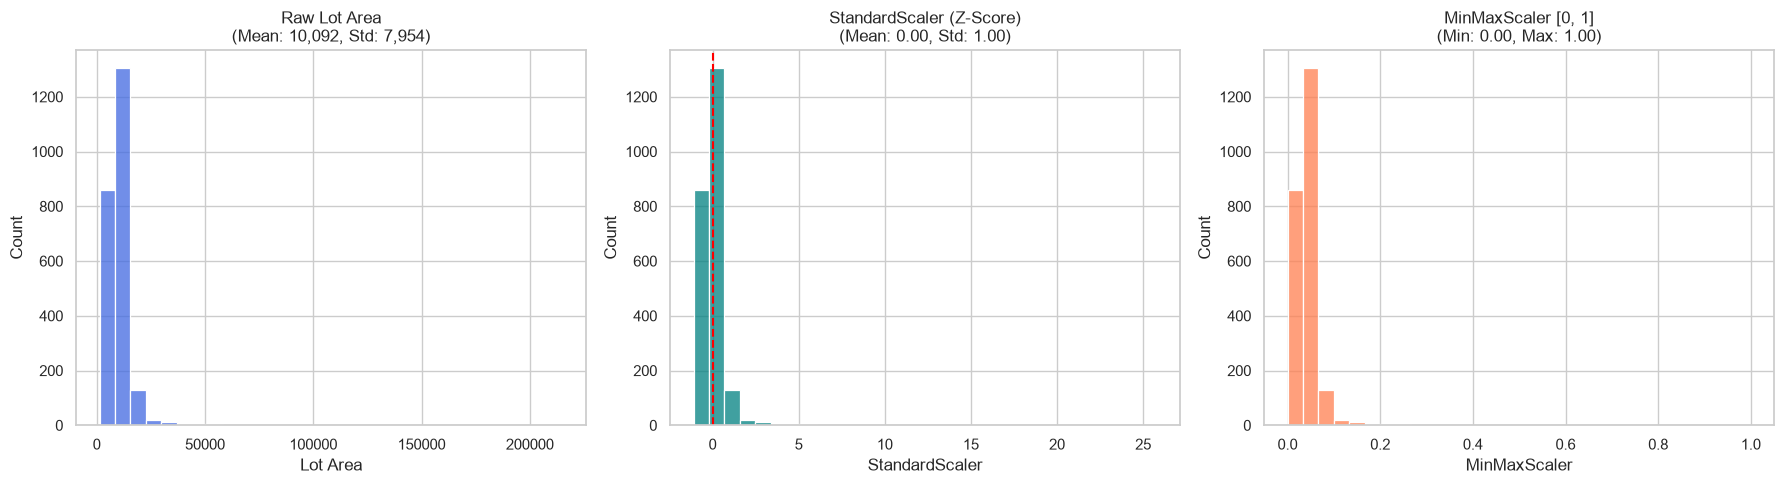

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# both scaling techniques comparison
sample_feature = X_train_encoded[['Lot Area']].copy()

std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

sample_feature['StandardScaler'] = std_scaler.fit_transform(sample_feature[['Lot Area']])
sample_feature['MinMaxScaler'] = minmax_scaler.fit_transform(sample_feature[['Lot Area']])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Raw
sns.histplot(sample_feature['Lot Area'], ax=axes[0], color='royalblue', bins=30)
axes[0].set_title(f"Raw Lot Area\n(Mean: {sample_feature['Lot Area'].mean():,.0f}, Std: {sample_feature['Lot Area'].std():,.0f})")

# 2. StandardScaler
sns.histplot(sample_feature['StandardScaler'], ax=axes[1], color='teal', bins=30)
axes[1].set_title(f"StandardScaler (Z-Score)\n(Mean: {sample_feature['StandardScaler'].mean():.2f}, Std: {sample_feature['StandardScaler'].std():.2f})")
axes[1].axvline(0, color='red', linestyle='--')

# 3. MinMaxScaler
sns.histplot(sample_feature['MinMaxScaler'], ax=axes[2], color='coral', bins=30)
axes[2].set_title(f"MinMaxScaler [0, 1]\n(Min: {sample_feature['MinMaxScaler'].min():.2f}, Max: {sample_feature['MinMaxScaler'].max():.2f})")

plt.tight_layout()
plt.show()


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 1. Identify final numeric and nominal columns after ordinal encoding
final_numeric_cols = X_train_encoded.select_dtypes(include=[np.number]).columns.tolist()
final_nominal_cols = X_train_encoded.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Features to StandardScale: {len(final_numeric_cols)}")
print(f"Features to One-Hot Encode: {len(final_nominal_cols)}")

# 2. Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), final_numeric_cols),
        ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), final_nominal_cols)
    ],
    verbose_feature_names_out=True
)

# 3. Fit on Train, Transform both Train and Test
X_train_processed = preprocessor.fit_transform(X_train_encoded)
X_test_processed = preprocessor.transform(X_test_encoded)

# 4. Extract generated feature names
feature_names = preprocessor.get_feature_names_out()

print("\n--- Pipeline Transformation Success ---")
print(f"Processed X_train shape: {X_train_processed.shape}")
print(f"Processed X_test shape:  {X_test_processed.shape}")
print(f"Total Features Generated: {len(feature_names)}")
print(f"\nFirst 5 Processed Feature Names:\n{feature_names[:5]}")


Features to StandardScale: 50
Features to One-Hot Encode: 29

--- Pipeline Transformation Success ---
Processed X_train shape: (2342, 253)
Processed X_test shape:  (586, 253)
Total Features Generated: 253

First 5 Processed Feature Names:
['num__MS SubClass' 'num__Lot Frontage' 'num__Lot Area'
 'num__Overall Qual' 'num__Overall Cond']


In [ ]:

X_train_df = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)


y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)


X_train_df.to_csv('../data/X_train_processed.csv', index=True)
X_test_df.to_csv('../data/X_test_processed.csv', index=True)

y_train.to_csv('../data/y_train.csv', index=True)
y_test.to_csv('../data/y_test.csv', index=True)

y_train_log.to_csv('../data/y_train_log.csv', index=True)
y_test_log.to_csv('../data/y_test_log.csv', index=True)

print("All preprocessed data successfully saved to '../data/' directory!")
print(f"Features: {X_train_df.shape[1]} columns ready for modeling.")


All preprocessed data successfully saved to '../data/' directory!
Features: 253 columns ready for modeling.


In [ ]:
### Summary of Milestone 2:

1. **Leakage Prevention:** Split 80/20 train/test before any transformations; removed 2 extreme outliers strictly from `X_train`.
2. **Domain Imputation:** 
   - Structural NAs mapped to 'None' (categorical) or 0 (numeric).
   - `Lot Frontage` imputed using neighborhood median with fallback to global median.
   - Result: 0 missing values across both train and test.
3. **Ordinal Encoding:** Encoded 10+ quality & condition ratings to numeric ranks (0 to 5).
4. **Feature Scaling:** Applied `StandardScaler` to all numeric and ordinal features.
5. **One-Hot Encoding:** Expanded nominal categorical columns using `handle_unknown='ignore'`.
6. **Unified ColumnTransformer:** Transformed 79 raw columns into 253 clean numeric features.
7. **Saved Artifacts:** Exported processed features and log-transformed targets for Milestones 3, 4, and 5.
